# Chapitre 9 - Cours 1 : la linéarisabilité

Répliquer les données protège des pannes, mais crée des copies qui peuvent diverger.
La garantie la plus forte qu'un système répliqué puisse offrir est de **se comporter
comme s'il n'existait qu'une seule copie** des données : c'est la **linéarisabilité**.
Ce notebook la définit précisément, construit un **vérificateur** qui décide si un
historique d'opérations est linéarisable, l'applique à des systèmes simulés (un registre
sur quorum, en particulier) et mesure ce qu'elle coûte. Il couvre la section *Consistency Guarantees* et toute la section *Linearizability* (*What Makes a System Linearizable?*, *Relying on Linearizability*, *Implementing Linearizable Systems*, *The Cost of Linearizability*) du chapitre.

**Plan.**

1. Cohérence à terme ou cohérence forte : l'illusion d'une copie unique.
2. Qu'est-ce qui rend un système linéarisable ? Un vérificateur exécutable.
3. Linéarisabilité contre sérialisabilité.
4. Quand a-t-on besoin de linéarisabilité ?
5. Quelles réplications sont linéarisables ? Le piège des quorums.
6. Le coût de la linéarisabilité : CAP et délais réseau.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.consistency import Op
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Cohérence à terme ou cohérence forte : l'illusion d'une copie unique (section *Consistency Guarantees*)

Au chapitre 5, nous avons vu qu'une base répliquée peut renvoyer des
résultats **périmés** (une réplique en retard) ou **contradictoires** (des écritures
concurrentes sur plusieurs leaders). Deux philosophies s'opposent pour vivre avec :

- la **cohérence à terme** (eventual consistency) : la réplication est visible de
  l'application, qui doit gérer elle-même les incohérences et les conflits ; la seule
  promesse est que les répliques **convergent** si l'on cesse d'écrire. Promesse faible :
  elle ne dit rien de **quand** ;
- la **cohérence forte** : le système masque la réplication et se comporte **comme un
  seul nœud**. C'est plus simple pour le développeur, mais plus lent, et certaines pannes
  qu'un système à cohérence à terme tolère le rendent indisponible.

Le livre compare ces garanties aux niveaux d'isolation des transactions du chapitre
7 : dans les deux cas, on échange de la simplicité contre de la
performance. Mais les deux hiérarchies répondent à des questions différentes :
l'isolation traite des **courses entre transactions concurrentes**, les modèles de
cohérence de la **coordination des répliques** face aux délais et aux pannes. Ce chapitre
explore le modèle le plus fort courant (la linéarisabilité), les garanties d'**ordre**
(causalité, ordre total) et enfin le **consensus**.

**L'idée de la linéarisabilité** (aussi appelée cohérence atomique, cohérence forte,
cohérence immédiate ou externe) : le système doit donner l'**illusion d'une copie unique**
des données, sur laquelle chaque opération s'exécute **atomiquement**. Conséquence
directe : dès qu'une écriture est terminée, **toute** lecture qui commence ensuite, par
n'importe quel client, voit la nouvelle valeur. C'est une **garantie de fraîcheur**
(recency guarantee).

Voici un système qui ne la respecte pas. Inès et Bastien suivent sur leur téléphone la
finale de leur équipe. Le score final est écrit sur le leader, qui le réplique de façon
asynchrone à deux suiveurs. Inès recharge la page, tombe sur le suiveur 1 (à jour), voit
le score final et **le crie** à Bastien, qui recharge à son tour... et tombe sur le
suiveur 2, en retard : pour lui le match n'est pas fini.

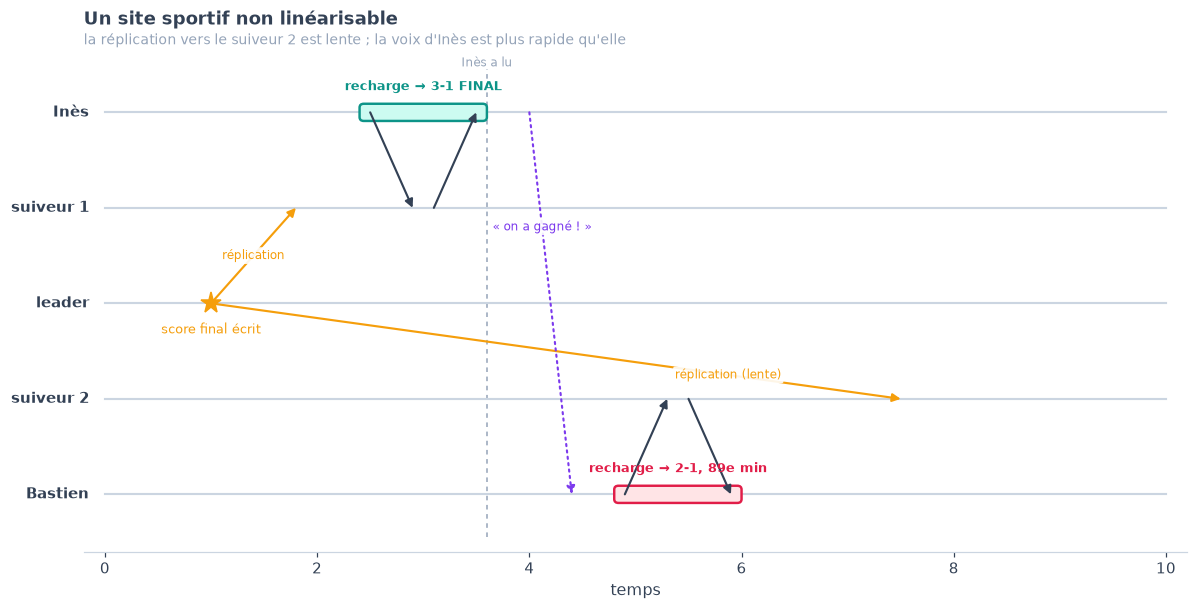

In [2]:
st = SpaceTime(["Inès", "suiveur 1", "leader", "suiveur 2", "Bastien"], t_max=10, width=11,
               title="Un site sportif non linéarisable",
               subtitle="la réplication vers le suiveur 2 est lente ; la voix d'Inès est plus rapide qu'elle")
st.event("leader", 1.0, "score final écrit", kind="star")
st.msg("leader", 1.0, "suiveur 1", 1.8, "réplication", color=AMBER)
st.msg("leader", 1.0, "suiveur 2", 7.5, "réplication (lente)", color=AMBER, label_pos=0.75)
st.op("Inès", 2.4, 3.6, "recharge → 3-1 FINAL", color=TEAL)
st.msg("Inès", 2.5, "suiveur 1", 2.9, "", color=SLATE)
st.msg("suiveur 1", 3.1, "Inès", 3.5, "", color=SLATE)
st.msg("Inès", 4.0, "Bastien", 4.4, "« on a gagné ! »", color=VIOLET, style="dotted", label_pos=0.3)
st.op("Bastien", 4.8, 6.0, "recharge → 2-1, 89e min", color=ROSE)
st.msg("Bastien", 4.9, "suiveur 2", 5.3, "", color=SLATE)
st.msg("suiveur 2", 5.5, "Bastien", 5.9, "", color=SLATE)
st.vline(3.6, "Inès a lu")
st.show()

Si les deux avaient rechargé **au même moment**, des résultats différents n'auraient
surpris personne. Mais Bastien **sait** qu'il a lancé sa requête **après** la réponse
reçue par Inès (il a entendu le cri) : il s'attend donc à un résultat au moins aussi
récent. La réponse périmée est une **violation de la linéarisabilité**. Remarquez que
l'anomalie n'est visible que grâce à un **second canal de communication** (la voix) :
nous y reviendrons en section 4.

> **À retenir.** La linéarisabilité donne l'illusion d'une copie unique, modifiée
> atomiquement : une lecture qui commence après la fin d'une écriture (ou d'une autre
> lecture) doit voir une valeur au moins aussi récente. C'est une garantie de fraîcheur.